# 08 · Đánh giá cuối trên tập test

Chấm 5 mô hình dự báo PM2.5 giờ kế tiếp trên cùng tập test theo thời gian. Persistence và Linear Regression là hai mốc đối chiếu. Random Forest, Gradient Boosting và MLP dùng các mô hình đã chốt từ notebook 05 và 07.

Đặt file trong `notebooks/` và dùng kernel đã chạy các notebook trước. Chọn **Run All** sau khi các mô hình đã được lưu. Với bản dữ liệu hiện tại, tập test dự kiến có **51.063 mẫu**. Nếu bật `SAVE_ARTIFACTS`, notebook xuất bảng điểm, biểu đồ và cập nhật nhật ký.

## 1. Nạp thư viện và xác định các mô hình

Dùng môi trường .venv cài theo requirements.txt (scikit-learn 1.7.2). Ưu tiên model trong models/; nếu baseline không có, tự dùng bản lưu trong outputs/experiments/experiments01/models/. Có thể đặt LINEAR_MODEL_PATH để chỉ định tệp khác. Bộ nạp kiểm tra phiên bản thư viện theo metadata trước khi nạp mô hình.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from threadpoolctl import threadpool_limits

CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = next(
    (folder for folder in (CURRENT_DIR, *CURRENT_DIR.parents) if (folder / "src").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Hãy mở notebook từ thư mục đồ án hoặc thư mục notebooks.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import TEST_START, load_data, time_split
from src.features import FFILL_LIMIT, PM25_LAGS, ROLLING_WINDOWS, add_features, split_xy

SAVE_ARTIFACTS = True
MODELS_DIR = PROJECT_ROOT / "models"
OUTPUTS_DIR = PROJECT_ROOT / "outputs" / "notebooks"
TABLES_DIR = OUTPUTS_DIR / "tables"
EXPERIMENT_LOG = PROJECT_ROOT / "experiment_log.csv"

from src.artifacts import MODEL_LABELS, load_saved_model, resolve_model_paths
from src.evaluation import export_analysis

# None: prefer models/, fall back to the archived baseline from experiments01.
# A custom relative path is resolved against PROJECT_ROOT.
LINEAR_MODEL_PATH = None
MODEL_PATHS = resolve_model_paths(PROJECT_ROOT, linear_model_path=LINEAR_MODEL_PATH)
MODELS = {key: (MODEL_LABELS[key], path) for key, path in MODEL_PATHS.items()}
print("Resolved model paths:")
for key, (_, path) in MODELS.items():
    print(key, path.relative_to(PROJECT_ROOT) if path.is_relative_to(PROJECT_ROOT) else path)


Resolved model paths:
baseline_linreg models\baseline_linear_regression.joblib
random_forest_tuned models\random_forest_tuned.joblib
gradient_boosting_tuned models\gradient_boosting_tuned.joblib
mlp_tuned models\mlp_tuned.joblib


## 2. Chuẩn bị tập test

Dùng các hàm trong `src/` giống notebook 07. `X_test` là bảng đặc trưng đưa cho mô hình, còn `y_test` chứa PM2.5 thực tế ở giờ kế tiếp để chấm điểm. Mốc chia dựa trên thời điểm của nhãn.

In [2]:
featured = add_features(load_data())
labeled = featured.dropna(subset=["target"]).reset_index(drop=True)
train_validation, test = time_split(labeled)
test = test.reset_index(drop=True)

X_tv, y_tv = split_xy(train_validation)
X_test, y_test = split_xy(test)
assert train_validation["target_datetime"].max() < TEST_START <= test["target_datetime"].min()
assert X_tv.columns.equals(X_test.columns)
assert X_test.index.equals(y_test.index)

print(f"Train + validation: {len(X_tv):,} mẫu.")
print(f"Test: {len(X_test):,} mẫu, {X_test.shape[1]} đặc trưng.")
print(f"Thời gian nhãn test: {test['target_datetime'].min()} đến {test['target_datetime'].max()}.")

Train + validation: 360,954 mẫu.
Test: 51,063 mẫu, 27 đặc trưng.
Thời gian nhãn test: 2016-09-01 00:00:00 đến 2017-02-28 23:00:00.


## 3. Dự báo trên cùng tập test

Persistence lấy PM2.5 ở giờ hiện tại làm dự báo giờ tiếp theo. Nếu giá trị hiện tại thiếu, dùng trung vị của `y_tv`, giống notebook 02. Với các mô hình còn lại, pipeline đã lưu tự áp dụng bước tiền xử lý khi gọi `predict`. Linear Regression dùng dự báo gốc như ở notebook 02.

In [3]:
fallback = float(y_tv.median())
current_pm25 = X_test["PM2.5"]
predictions = {"baseline_persistence": current_pm25.fillna(fallback).to_numpy()}
labels = {"baseline_persistence": "Persistence"}
print(f"Persistence dùng giá trị dự phòng ở {current_pm25.isna().sum():,} mẫu.")

for key, (label, model_path) in MODELS.items():
    with threadpool_limits(limits=1):
        model = load_saved_model(key, model_path)
        predictions[key] = np.asarray(model.predict(X_test)).ravel()

    labels[key] = label
    print(f"{label}: nạp {model_path.name}, tạo {len(predictions[key]):,} dự báo.")

for key, values in predictions.items():
    if values.shape != (len(y_test),) or not np.isfinite(values).all():
        raise ValueError(f"Dự báo của {labels[key]} thiếu dòng hoặc có giá trị không hợp lệ.")

Persistence dùng giá trị dự phòng ở 33 mẫu.
Linear Regression: nạp baseline_linear_regression.joblib, tạo 51,063 dự báo.


Random Forest - tuned: nạp random_forest_tuned.joblib, tạo 51,063 dự báo.


C:\Users\ASUS TUF\Documents\GitHub\sgu_finalproject_machinelearning_2026-2027\.venv\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
found 0 physical cores < 1
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\ASUS TUF\Documents\GitHub\sgu_finalproject_machinelearning_2026-2027\.venv\Lib\site-packages\joblib\externals\loky\backend\context.py", line 255, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")


Gradient Boosting - tuned: nạp gradient_boosting_tuned.joblib, tạo 51,063 dự báo.
MLP - tuned: nạp mlp_tuned.joblib, tạo 51,063 dự báo.


## 4. Tính MAE, RMSE và R²

MAE là độ lệch tuyệt đối trung bình. RMSE nhạy hơn với những dự đoán lệch nhiều. Cả hai đo bằng µg/m³, càng thấp càng tốt. R² càng cao càng tốt. Bảng xếp hạng theo RMSE test.

In [4]:
scores = []
for key, prediction in predictions.items():
    scores.append({
        "experiment_id": f"{key}_test",
        "model": labels[key],
        "mae": mean_absolute_error(y_test, prediction),
        "rmse": np.sqrt(mean_squared_error(y_test, prediction)),
        "r2": r2_score(y_test, prediction),
        "n_test": len(y_test),
    })

test_metrics = pd.DataFrame(scores).sort_values("rmse", ignore_index=True)
test_metrics.insert(0, "rank", test_metrics["rmse"].rank(method="min").astype(int))
display(test_metrics[["rank", "model", "mae", "rmse", "r2", "n_test"]].round(4))

,rank,model,mae,rmse,r2,n_test
0,1,Random Forest - tuned,10.5906,20.9613,0.9550,51063
1,2,Gradient Boosting - tuned,10.8195,21.2957,0.9536,51063
2,3,MLP - tuned,11.1583,21.4967,0.9527,51063
3,4,Linear Regression,11.3510,21.8027,0.9513,51063
4,5,Persistence,11.5864,23.1133,0.9453,51063


## 5. Biểu đồ và kết luận

Biểu đồ so sánh RMSE của 5 mô hình. Dùng kết quả để báo cáo hiệu năng trên test. Cấu hình các mô hình được chốt từ validation trước khi chấm.

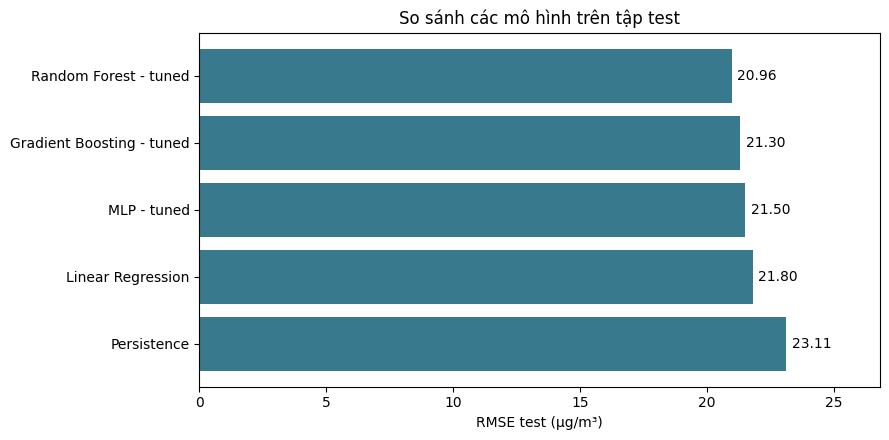

RMSE test thấp nhất: Random Forest - tuned (20.9613 µg/m³).
RMSE thấp nhất giảm 9.31% so với Persistence.


In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(test_metrics["model"], test_metrics["rmse"], color="#39798e")
ax.invert_yaxis()
ax.set_xlabel("RMSE test (µg/m³)")
ax.set_title("So sánh các mô hình trên tập test")
ax.set_xlim(0, test_metrics["rmse"].max() * 1.16)
ax.bar_label(bars, fmt="%.2f", padding=4)
fig.tight_layout()
plt.show()

best = test_metrics.iloc[0]
baseline_rmse = test_metrics.loc[
    test_metrics["experiment_id"].eq("baseline_persistence_test"), "rmse"
].item()
print(f"RMSE test thấp nhất: {best['model']} ({best['rmse']:.4f} µg/m³).")
if baseline_rmse > 0:
    reduction = 100 * (baseline_rmse - best["rmse"]) / baseline_rmse
    print(f"RMSE thấp nhất giảm {reduction:.2f}% so với Persistence.")

## 6. Lưu kết quả và cập nhật nhật ký

Khi `SAVE_ARTIFACTS = True`, lưu bảng điểm vào `outputs/notebooks/tables/final_test_metrics.csv` và hình vào `outputs/notebooks/figures/final_test_rmse.png`. Nhật ký `experiment_log.csv` cập nhật theo mã thí nghiệm có đuôi `_test`. Hai dòng test cho Persistence và Linear Regression dùng cùng mã với notebook 02.

In [6]:
if SAVE_ARTIFACTS:
    figures_dir = OUTPUTS_DIR / "figures"
    figures_dir.mkdir(parents=True, exist_ok=True)
    TABLES_DIR.mkdir(parents=True, exist_ok=True)
    metrics_path = TABLES_DIR / "final_test_metrics.csv"
    figure_path = figures_dir / "final_test_rmse.png"

    dataset_version = (
        f"beijing_air_quality_standardized.csv; ffill<={FFILL_LIMIT}h; "
        f"lags={'/'.join(map(str, PM25_LAGS))}; rolling={'/'.join(map(str, ROLLING_WINDOWS))}"
    )
    log_rows = (
        test_metrics[["experiment_id", "model", "mae", "rmse", "r2"]]
        .rename(columns={"model": "model_name"})
        .round({"mae": 6, "rmse": 6, "r2": 6})
    )
    log_rows.insert(2, "dataset_version", dataset_version)
    log_rows["notes"] = (
        f"Final test, {len(y_test)} rows with labels from {TEST_START:%Y-%m-%d}. "
        "Configurations fixed before test evaluation."
    )
    if EXPERIMENT_LOG.is_file() and EXPERIMENT_LOG.stat().st_size:
        existing_log = pd.read_csv(EXPERIMENT_LOG, encoding="utf-8-sig")
        existing_log = existing_log.loc[~existing_log["experiment_id"].isin(log_rows["experiment_id"])]
        log_rows = pd.concat([existing_log, log_rows], ignore_index=True)

    test_metrics.to_csv(metrics_path, index=False, encoding="utf-8-sig")
    fig.savefig(figure_path, dpi=150, bbox_inches="tight")
    log_rows.to_csv(EXPERIMENT_LOG, index=False, encoding="utf-8-sig")
    for path in (metrics_path, figure_path, EXPERIMENT_LOG):
        print("Đã lưu:", path.relative_to(PROJECT_ROOT))

Đã lưu: outputs\notebooks\tables\final_test_metrics.csv
Đã lưu: outputs\notebooks\figures\final_test_rmse.png
Đã lưu: experiment_log.csv


## 7. Phân tích sai số và độ chắc chắn của mô hình đã chốt

Lưu riêng vào outputs/experiments/final_test/analysis/: dự đoán từng mẫu, sai số theo trạm/tháng/mùa/mức PM2.5, các trường hợp sai số lớn, hình residual và chuỗi thời gian, manifest truy vết. Khoảng bootstrap ghép cặp dùng khối 7 ngày, giữ các trạm cùng thời điểm trong cùng khối. Khoảng này chỉ mô tả độ bất định có điều kiện trên các dự đoán cố định trong giai đoạn test đã quan sát; không dùng để chọn lại mô hình. Residual = y_true - y_pred; nhóm nồng độ đóng bên phải, ví dụ 35 thuộc <=35.


In [7]:
prediction_frame = test[["station", "datetime", "target_datetime"]].reset_index(drop=True).copy()
prediction_frame["y_true"] = y_test.to_numpy()
for key, values in predictions.items():
    prediction_frame[f"pred_{key}"] = values

if SAVE_ARTIFACTS:
    analysis_tables = export_analysis(prediction_frame, MODEL_PATHS)
    display(analysis_tables["final_test_error_by_pm25_level.csv"])
    display(analysis_tables["paired_model_uncertainty.csv"])
    print("Đã lưu phân tích bổ sung vào outputs/experiments/final_test/analysis/")
else:
    print("Bật SAVE_ARTIFACTS để xuất phân tích bổ sung.")


,experiment_id,model,pm25_level,n,mean_pm25,mae,rmse,r2,mean_residual
0,baseline_persistence_test,Persistence,<=35,20149,15.120502,5.694178,15.291351,-2.104748,-1.924264
1,baseline_linreg_test,Linear Regression,<=35,20149,15.120502,6.518740,14.924427,-1.957536,-2.554184
2,random_forest_tuned_test,Random Forest - tuned,<=35,20149,15.120502,5.186846,13.501549,-1.420482,-2.623358
3,gradient_boosting_tuned_test,Gradient Boosting - tuned,<=35,20149,15.120502,5.102083,13.091040,-1.275532,-2.354226
4,mlp_tuned_test,MLP - tuned,<=35,20149,15.120502,5.124942,12.947526,-1.225913,-2.079798
5,baseline_persistence_test,Persistence,"(35,75]",8881,54.462448,10.667380,20.818606,-2.315167,-1.382164
6,baseline_linreg_test,Linear Regression,"(35,75]",8881,54.462448,10.262634,19.595394,-1.937041,-4.343519
7,random_forest_tuned_test,Random Forest - tuned,"(35,75]",8881,54.462448,9.506686,17.767127,-1.414552,-2.236524
8,gradient_boosting_tuned_test,Gradient Boosting - tuned,"(35,75]",8881,54.462448,9.389374,17.202681,-1.263572,-2.341014
9,mlp_tuned_test,MLP - tuned,"(35,75]",8881,54.462448,9.576069,16.287437,-1.029119,-1.443281


,model_a,model_b,rmse_difference_a_minus_b,ci_95_low,ci_95_high,n_bootstrap,block_days,seed,n_calendar_days,method
0,Random Forest - tuned,Persistence,-2.152007,-2.555324,-1.769920,2000,7,42,181,paired moving calendar-day blocks; all station...
1,Random Forest - tuned,Linear Regression,-0.841427,-1.125139,-0.593013,2000,7,42,181,paired moving calendar-day blocks; all station...
2,Random Forest - tuned,Gradient Boosting - tuned,-0.334417,-0.779941,0.133864,2000,7,42,181,paired moving calendar-day blocks; all station...
3,Random Forest - tuned,MLP - tuned,-0.535406,-1.343128,0.255698,2000,7,42,181,paired moving calendar-day blocks; all station...


Đã lưu phân tích bổ sung vào outputs/experiments/final_test/analysis/


## 8. Kết quả validation dùng cho báo cáo

Ô sau chạy lại đúng các cấu hình hiện có: importance RF trên train/validation fold 5, ba seed MLP và kiểm tra epoch ở hai fold đầu. Không đổi model cuối hoặc chọn theo test. CSV và bảng xuất phát từ lần chạy notebook này; không nhập số bằng tay.


In [8]:
from src.validation_diagnostics import run_diagnostics

if SAVE_ARTIFACTS:
    diagnostic_tables = run_diagnostics(return_tables=True)
    display(diagnostic_tables["rf_group_permutation_importance.csv"])
    display(diagnostic_tables["mlp_seed_summary.csv"])
    display(diagnostic_tables["mlp_validation_diagnostics.csv"])
else:
    diagnostic_tables = {}
    print("SAVE_ARTIFACTS=False: không chạy phần chẩn đoán có ghi file.")


RF validation importance complete.


MLP seed=7, fold=1: RMSE=26.5167


MLP seed=7, fold=2: RMSE=15.8630


MLP seed=7, fold=3: RMSE=18.7439


MLP seed=7, fold=4: RMSE=18.1713


MLP seed=7, fold=5: RMSE=18.3390


... (9 outputs left out)

MLP seed=2026, fold=5: RMSE=17.8731


,model,fold,feature_group,baseline_sample_rmse,rmse_increase_mean,rmse_increase_std,n_repeats,n_validation_sample,seed
0,Random Forest - tuned; refitted on fold 5 trai...,5,current_pm25,17.551848,51.861657,0.096242,5,30000,42
1,Random Forest - tuned; refitted on fold 5 trai...,5,other_pollutants,17.551848,5.939793,0.050297,5,30000,42
2,Random Forest - tuned; refitted on fold 5 trai...,5,pm25_lags_rolling,17.551848,2.090541,0.065781,5,30000,42
3,Random Forest - tuned; refitted on fold 5 trai...,5,weather,17.551848,1.441548,0.033483,5,30000,42
4,Random Forest - tuned; refitted on fold 5 trai...,5,time,17.551848,0.079964,0.011028,5,30000,42
5,Random Forest - tuned; refitted on fold 5 trai...,5,station,17.551848,0.002952,0.000614,5,30000,42


,seed,mae,rmse,r2
0,7,11.115137,19.526795,0.934524
1,42,11.071820,19.631728,0.933902
2,2026,11.017090,19.295069,0.936114


,diagnostic,fold,mae,rmse,r2,mean_residual,train_rmse,seed,max_iter,epochs,convergence_warning
0,seed_stability,1,16.616487,26.516724,0.915409,-4.535014,16.570121,7,40,40,True
1,seed_stability,2,9.548547,15.862996,0.950436,-0.635725,18.165998,7,40,32,False
2,seed_stability,3,10.610020,18.743948,0.932825,1.266146,17.142575,7,40,20,False
3,seed_stability,4,9.893523,18.171313,0.961637,-0.728327,17.632184,7,40,21,False
4,seed_stability,5,8.907110,18.338996,0.912316,1.540910,17.408638,7,40,15,False
5,seed_stability,1,15.994000,26.172736,0.917589,-3.074260,16.523206,42,40,40,True
6,seed_stability,2,9.560970,15.983276,0.949681,0.682691,17.802950,42,40,40,True
7,seed_stability,3,10.663935,18.898936,0.931709,-1.076971,17.421032,42,40,20,False
8,seed_stability,4,10.242345,18.598454,0.959812,2.870548,17.857911,42,40,21,False
9,seed_stability,5,8.897852,18.505241,0.910719,2.294444,17.257925,42,40,22,False


## Bằng chứng notebook cho các bảng CSV

Các bảng dưới đây được xuất từ biến đã tính trong notebook, kèm mã ô và hash. scripts/verify_result_sources.py kiểm tra CSV khớp output số liệu của notebook; không dùng W&B/MLflow hoặc thêm thư viện.


In [9]:
from src.notebook_evidence import record_tables, display_evidence
if SAVE_ARTIFACTS:
    from src.artifacts import load_saved_model
    config_rows=[]
    for key,path in MODEL_PATHS.items():
        fitted=load_saved_model(key,path)
        estimator=fitted.steps[-1][1]
        estimator=getattr(estimator,"regressor_",estimator)
        config_rows.append({
            "model": MODEL_LABELS[key], "estimator": type(estimator).__name__,
            "raw_input_columns": fitted.n_features_in_,
            "transformed_columns": len(fitted.steps[0][1].get_feature_names_out()),
            "layer_shapes": str([list(a.shape) for a in estimator.coefs_]) if hasattr(estimator,"coefs_") else None,
            "loss": estimator.get_params().get("loss"),
            "criterion": estimator.get_params().get("criterion"),
            "alpha": estimator.get_params().get("alpha")
        })
    model_configurations=pd.DataFrame(config_rows)
    improvement_rows=[]
    for reference in ["Persistence","Linear Regression"]:
        ref=test_metrics.loc[test_metrics.model.eq(reference)].iloc[0]
        for row in test_metrics.itertuples():
            improvement_rows.append({
                "model": row.model, "reference": reference,
                "rmse_reduction_percent": 100*(1-row.rmse/ref.rmse),
                "mae_reduction_percent": 100*(1-row.mae/ref.mae)
            })
    final_improvements=pd.DataFrame(improvement_rows)
    display(final_improvements)
    evidence_tables={"outputs/notebooks/tables/final_test_relative_improvements.csv":final_improvements,
                     "outputs/notebooks/tables/final_test_metrics.csv":test_metrics,
                     "outputs/notebooks/tables/final_model_configuration.csv":model_configurations,
                     **{f"outputs/experiments/final_test/analysis/{name}":table for name,table in analysis_tables.items()},
                     **{f"outputs/experiments/validation_diagnostics/{name}":table for name,table in diagnostic_tables.items()}}
    display(model_configurations)
    display_evidence(record_tables("notebooks/08_final_evaluation.ipynb","evidence-nb-08",evidence_tables))


,model,reference,rmse_reduction_percent,mae_reduction_percent
0,Random Forest - tuned,Persistence,9.310698,8.595105
1,Gradient Boosting - tuned,Persistence,7.863839,6.619556
2,MLP - tuned,Persistence,6.994254,3.695193
3,Linear Regression,Persistence,5.670247,2.032283
4,Persistence,Persistence,0.000000,0.000000
5,Random Forest - tuned,Linear Regression,3.859282,6.698964
6,Gradient Boosting - tuned,Linear Regression,2.325450,4.682434
7,MLP - tuned,Linear Regression,1.403594,1.697407
8,Linear Regression,Linear Regression,0.000000,0.000000
9,Persistence,Linear Regression,-6.011091,-2.074441


,model,estimator,raw_input_columns,transformed_columns,layer_shapes,loss,criterion,alpha
0,Linear Regression,LinearRegression,27,79,None,None,None,NaN
1,Random Forest - tuned,RandomForestRegressor,27,79,None,None,squared_error,NaN
2,Gradient Boosting - tuned,HistGradientBoostingRegressor,27,79,None,squared_error,None,NaN
3,MLP - tuned,MLPRegressor,27,79,"[[79, 32], [32, 16], [16, 1]]",squared_error,None,0.0001


C:\Users\ASUS TUF\Documents\GitHub\sgu_finalproject_machinelearning_2026-2027\src\notebook_evidence.py:70: FutureWarning: Mismatched null-like values nan and None found. In a future version, pandas equality-testing functions (e.g. assert_frame_equal) will consider these not-matching and raise.
  pd.testing.assert_frame_equal(actual, table, check_dtype=False, check_exact=False,


Notebook evidence: notebooks/08_final_evaluation.ipynb / evidence-nb-08 / computed / 15 CSV files